# RTENSO2026 2015/16 El Nino: anomaly maps and pattern ACC

Case-study companion to ESP-Lab `1a_*_leadtime_acc_skill_map.ipynb` and
`1b_*_leadtime_rmse_skill_map.ipynb`. With one target year, the ACC is the
**spatial** anomaly correlation (area-weighted, centred) between the forecast and
observed anomaly maps, computed per lead season, per member and for the ensemble
mean, over several regions; the RMSE is the matching area-weighted map error.

Anomalies remove the Reanalysis 1981-2010 lead-time climatology (lead-drift corrected
for Feb/Aug starts, see `CLIM_METHOD`) and the 1981-2010 observed monthly climatology. `TS` is verified
against HadISST2 over ice-free ocean (60S-60N) only; `TREFHT` and `PSL` against ERA5; `PRECT` against
GPCP v2.3.

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline

from datetime import datetime

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs

from matplotlib.colors import BoundaryNorm
from cartopy.util import add_cyclic_point
from esp_lab.utils import colormap_utils as mycolors
from esp_lab.utils.netcdf_utils import atomic_to_netcdf

import rtenso_case as rc

def to_datetime(times):
    return [datetime(t.year, t.month, 15) for t in np.atleast_1d(times)]

In [2]:
MAP_STYLE = {
    # field: (contour interval, min, max, colormap)
    "TS": (0.25, -3.0, 3.0, "blue2red"),
    "TREFHT": (0.25, -3.0, 3.0, "blue2red"),
    "PRECT": (0.5, -5.0, 5.0, "BrBG"),
    "PSL": (0.5, -6.0, 6.0, "blue2red"),
    "U850": (0.5, -6.0, 6.0, "blue2red"),
}


def map_cmap(name, ci, cmin, cmax):
    if name == "blue2red":
        cmap = mycolors.blue2red_cmap(np.arange(cmin, cmax + ci, ci))
    else:
        cmap = plt.get_cmap(name)
    return cmap


def draw_map(fig, da, nrow, ncol, index, title, field, scale=1.0):
    # Robinson map in the ESP-Lab style; NaN (e.g. land for SST) is drawn light grey.
    ci, cmin, cmax, cmap = MAP_STYLE[field]
    ci, cmin, cmax = ci * scale, cmin * scale, cmax * scale
    levels = np.arange(cmin, cmax + ci / 2, ci)
    cmap = map_cmap(cmap, ci, cmin, cmax)
    norm = BoundaryNorm(levels, ncolors=cmap.N)
    values, lon = add_cyclic_point(da.values, coord=da["lon"].values)
    values = np.ma.filled(values, np.nan)  # cartopy wraps pcolormesh only with transparent missing values
    ax = fig.add_subplot(nrow, ncol, index, projection=ccrs.Robinson(central_longitude=180))
    ax.set_facecolor("0.85")  # missing values (e.g. land for SST) show as light grey
    cntr = ax.pcolormesh(lon, da["lat"].values, values, cmap=cmap, norm=norm,
                         shading="nearest", rasterized=True, transform=ccrs.PlateCarree())
    ax.coastlines(lw=0.5)
    ax.set_global()
    ax.set_title(title, fontsize=10)
    return ax, cntr

### Run controls

In [3]:
derivation_mode = "auto"
CLIM_METHOD = "lead_drift"         # Feb/Aug drift correction: "lead_drift" or "target_month"

FIELD = "TS"                       # TS, TREFHT, PRECT, PSL
INIT_MONTHS = [2, 5, 8, 11]
MONTH_NAMES = {2: "Feb", 5: "May", 8: "Aug", 11: "Nov"}

# Hindcast year and cases. Each case reads
# <raw_model_root>/<case_prefix>_<CASE_YEAR><MM>0100/ENxx/post/...; "source" names
# the cached skill files, "init_months" the starts the case has.
CASE_YEAR = 2015
MODEL_PREFIX = "WCYCL20TR_ne30pg2_r05_IcoswISC30E3r5"
CASES = {
    "Reanalysis-CLIM": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_clim",
        "source": "RTENSO2026_clim",
        "init_months": (2, 5, 8, 11),
        "color": "tab:blue",
    },
    "Reanalysis-OBS": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_obs",
        "source": "RTENSO2026_obs",
        "init_months": (2, 5, 8, 11),
        "color": "tab:orange",
    },
    # Placeholder: obs ICs with NSIDCv6 sea ice; set init_months once the runs are post-processed.
    "RTENSO2026-obs-nsidc": {
        "case_prefix": f"{MODEL_PREFIX}_RTENSO2026_obs_ice_nsidc",
        "source": "RTENSO2026_obs_ice_nsidc",
        "init_months": (),
        "color": "tab:red",
    },
    "Reanalysis-FOSIRL": {
        "case_prefix": f"{MODEL_PREFIX}_BruteForce",
        "source": "Reanalysis",
        "init_months": (2, 5, 8, 11),
        "color": "tab:green",
    },
}
CASES = {name: case for name, case in CASES.items() if case["init_months"]}   # drop placeholders
FOCUS = {"label": "DJF 2015/16", "months": [(2015, 12), (2016, 1), (2016, 2)]}
ACC_REGIONS = ["Global", "Tropics", "TropPacific", "NHextratropics", "NorthAmerica"]

OUTDIR = rc.diag_dir("RTENSO2026", "case_study", "pattern_skill", rc.FIELDS[FIELD]["realm"], FIELD)
OUTDIR.mkdir(parents=True, exist_ok=True)

### Load anomalies

In [4]:
%%time
obs = rc.obs_anomaly(FIELD, mode=derivation_mode)

anoms = {}
for case in CASES:
    for init in INIT_MONTHS:
        if init not in CASES[case]["init_months"]:
            continue
        anom = rc.hindcast_anomaly(CASES[case]["case_prefix"], init, FIELD, year=CASE_YEAR,
                                   method=CLIM_METHOD, mode=derivation_mode)
        if anom is None:
            print(f"[{case} init{init:02d}] not available")
            continue
        obs_matched = rc.match_obs(anom, obs)
        if FIELD == "TS":  # verify SST: ice-free ocean (HadISST2 ocean points within 60S-60N)
            obs_matched = obs_matched.where(abs(obs_matched["lat"]) <= 60.0)
            anom = anom.where(obs_matched.notnull())
        anoms[(case, init)] = (anom, obs_matched)
        print(f"[{case} init{init:02d}] {anom.sizes['member']} members; {anom.attrs['climatology_method']}")

[RTENSO2026-clim init02] 10 members; HadISST2 1981-2010 target-month climatology + Reanalysis init05/init11 mean drift at the same lead
[RTENSO2026-clim init05] 10 members; Reanalysis init05 1981-2010
[RTENSO2026-clim init08] 10 members; HadISST2 1981-2010 target-month climatology + Reanalysis init05/init11 mean drift at the same lead
[RTENSO2026-clim init11] 10 members; Reanalysis init11 1981-2010
[RTENSO2026-obs init02] 10 members; HadISST2 1981-2010 target-month climatology + Reanalysis init05/init11 mean drift at the same lead
[RTENSO2026-obs init05] 10 members; Reanalysis init05 1981-2010
[RTENSO2026-obs init08] 10 members; HadISST2 1981-2010 target-month climatology + Reanalysis init05/init11 mean drift at the same lead
[RTENSO2026-obs init11] 10 members; Reanalysis init11 1981-2010
[Reanalysis-2015 init02] 10 members; HadISST2 1981-2010 target-month climatology + Reanalysis init05/init11 mean drift at the same lead
[Reanalysis-2015 init05] 10 members; Reanalysis init05 1981-2010

### Focus-season anomaly maps

Ensemble-mean anomalies over the focus season from every start, with the global pattern ACC in each title.

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_anomaly_map_ts_djf_201516.png


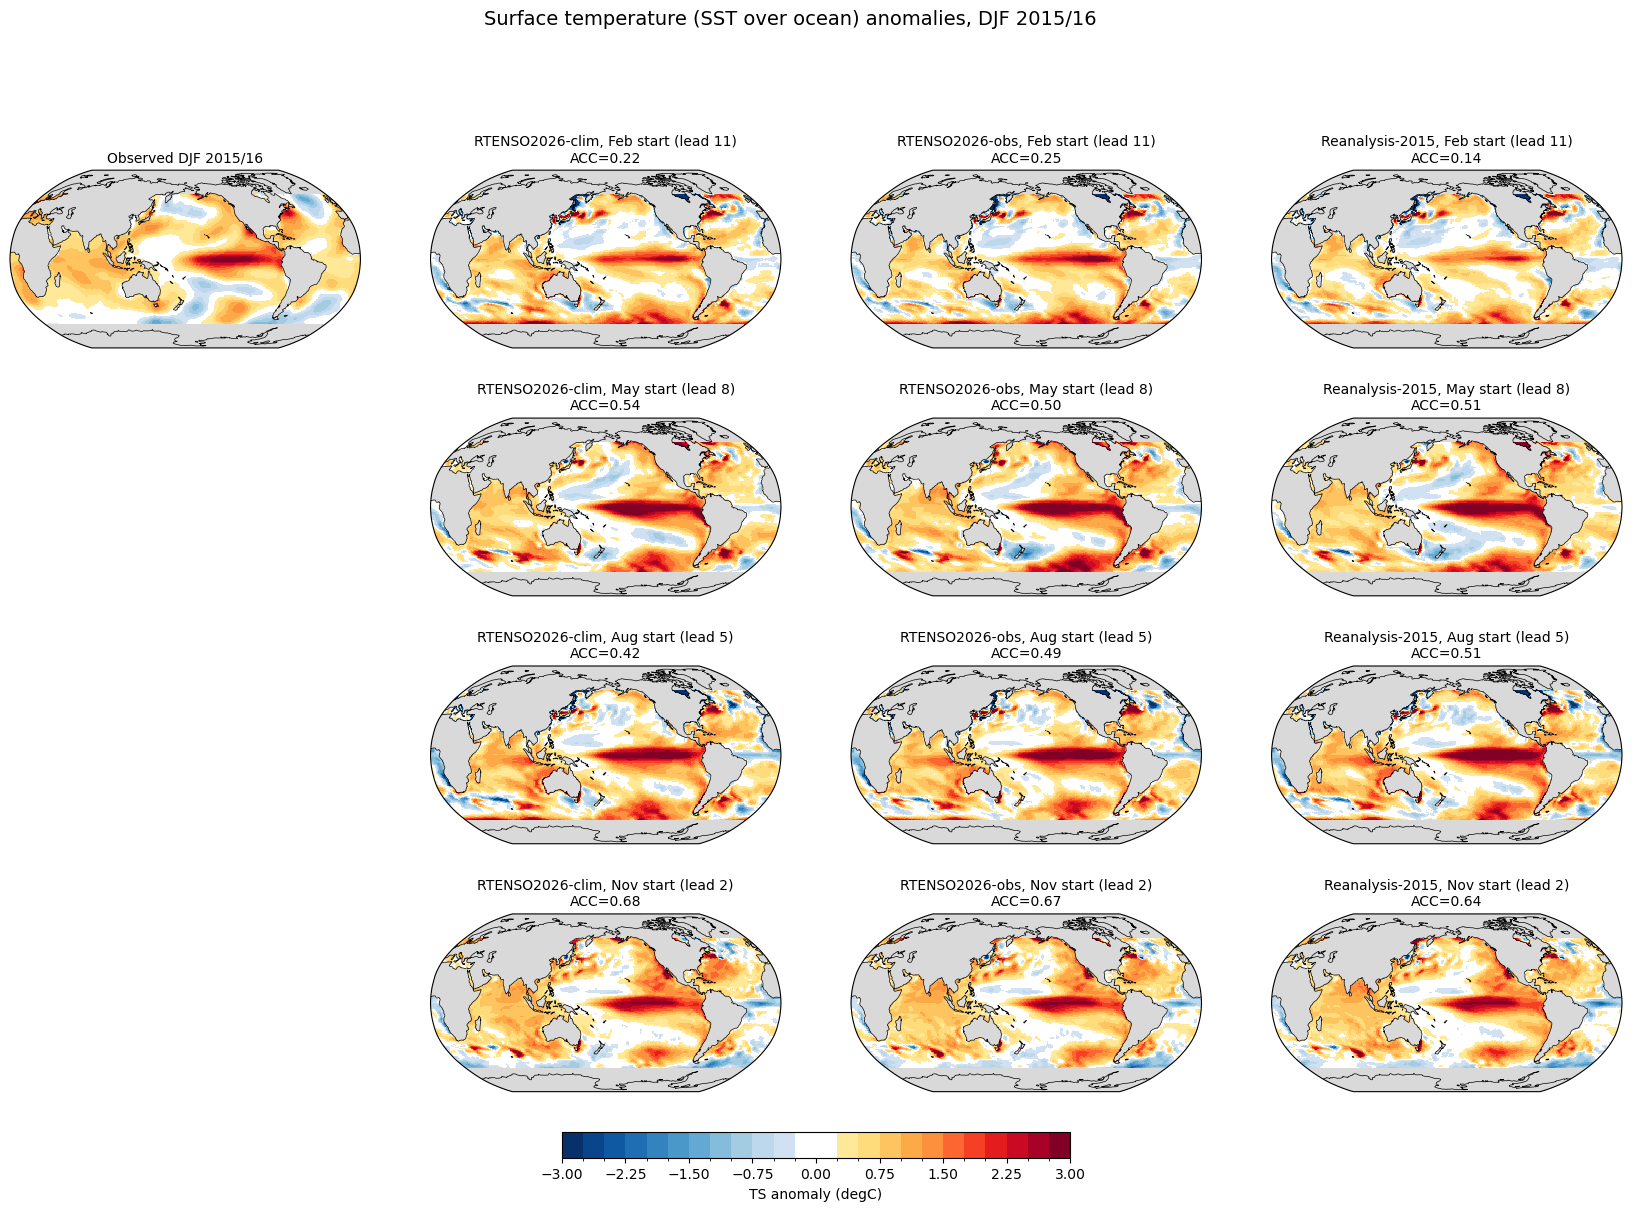

In [5]:
ncol = 1 + len(CASES)
fig = plt.figure(figsize=(5.2 * ncol, 3.3 * len(INIT_MONTHS)))
obs_focus = rc.obs_target_mean(obs, FOCUS["months"])
if FIELD == "TS":
    obs_focus = obs_focus.where(abs(obs_focus["lat"]) <= 60.0)
ax, cntr = draw_map(fig, obs_focus, len(INIT_MONTHS), ncol, 1, f"Observed {FOCUS['label']}", FIELD)
for row, init in enumerate(INIT_MONTHS):
    for col, case in enumerate(CASES, start=1):
        if (case, init) not in anoms:
            continue
        anom, _ = anoms[(case, init)]
        focus = rc.target_mean(anom.mean("member"), FOCUS["months"])
        if focus is None:
            continue
        acc = float(rc.pattern_acc(focus, obs_focus, "Global"))
        lead = [i for i, t in enumerate(anom["time"].values) if (t.year, t.month) == FOCUS["months"][1]][0]
        draw_map(fig, focus, len(INIT_MONTHS), ncol, row * ncol + col + 1,
                 f"{case}, {MONTH_NAMES[init]} start (lead {lead})\nACC={acc:.2f}", FIELD)
cbar = fig.colorbar(cntr, ax=fig.axes, orientation="horizontal", fraction=0.025, pad=0.04, shrink=0.6)
cbar.set_label(f"{FIELD} anomaly ({rc.FIELDS[FIELD]['units']})")
fig.suptitle(f"{rc.FIELDS[FIELD]['long_name']} anomalies, {FOCUS['label']}", fontsize=14)
print(rc.save_figure(fig, "rtenso2026", "anomaly_map", FIELD, FOCUS["label"].replace("/", "")))
plt.show()

### Pattern ACC and RMSE by lead season

Non-overlapping 3-month lead seasons (season 1 = leads 0-2), as in the 1a/1b seasonal products.

In [6]:
%%time
metrics = {}
for (case, init), (anom, obs_matched) in anoms.items():
    fc_seas = rc.seasonal_leads(anom)
    ob_seas = rc.seasonal_leads(obs_matched)
    ens_seas = fc_seas.mean("member")
    metrics[(case, init)] = xr.Dataset({
        "acc_ens": xr.concat([rc.pattern_acc(ens_seas, ob_seas, r) for r in ACC_REGIONS], dim="region"),
        "acc_member": xr.concat([rc.pattern_acc(fc_seas, ob_seas, r) for r in ACC_REGIONS], dim="region"),
        "rmse_ens": xr.concat([rc.pattern_rmse(ens_seas, ob_seas, r) for r in ACC_REGIONS], dim="region"),
        "rmse_member": xr.concat([rc.pattern_rmse(fc_seas, ob_seas, r) for r in ACC_REGIONS], dim="region"),
    }).assign_coords(region=ACC_REGIONS).load()
    source = CASES[case]["source"]
    atomic_to_netcdf(metrics[(case, init)].drop_vars("time"),
                     OUTDIR / f"{source}_init{init:02d}_{FIELD}_pattern_skill_y{CASE_YEAR}_clim_{rc.CLIM_YEARS[0]}_{rc.CLIM_YEARS[1]}_s8.nc")

CPU times: user 10.2 s, sys: 7.18 s, total: 17.4 s
Wall time: 17.9 s


/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_pattern_acc_ts.png


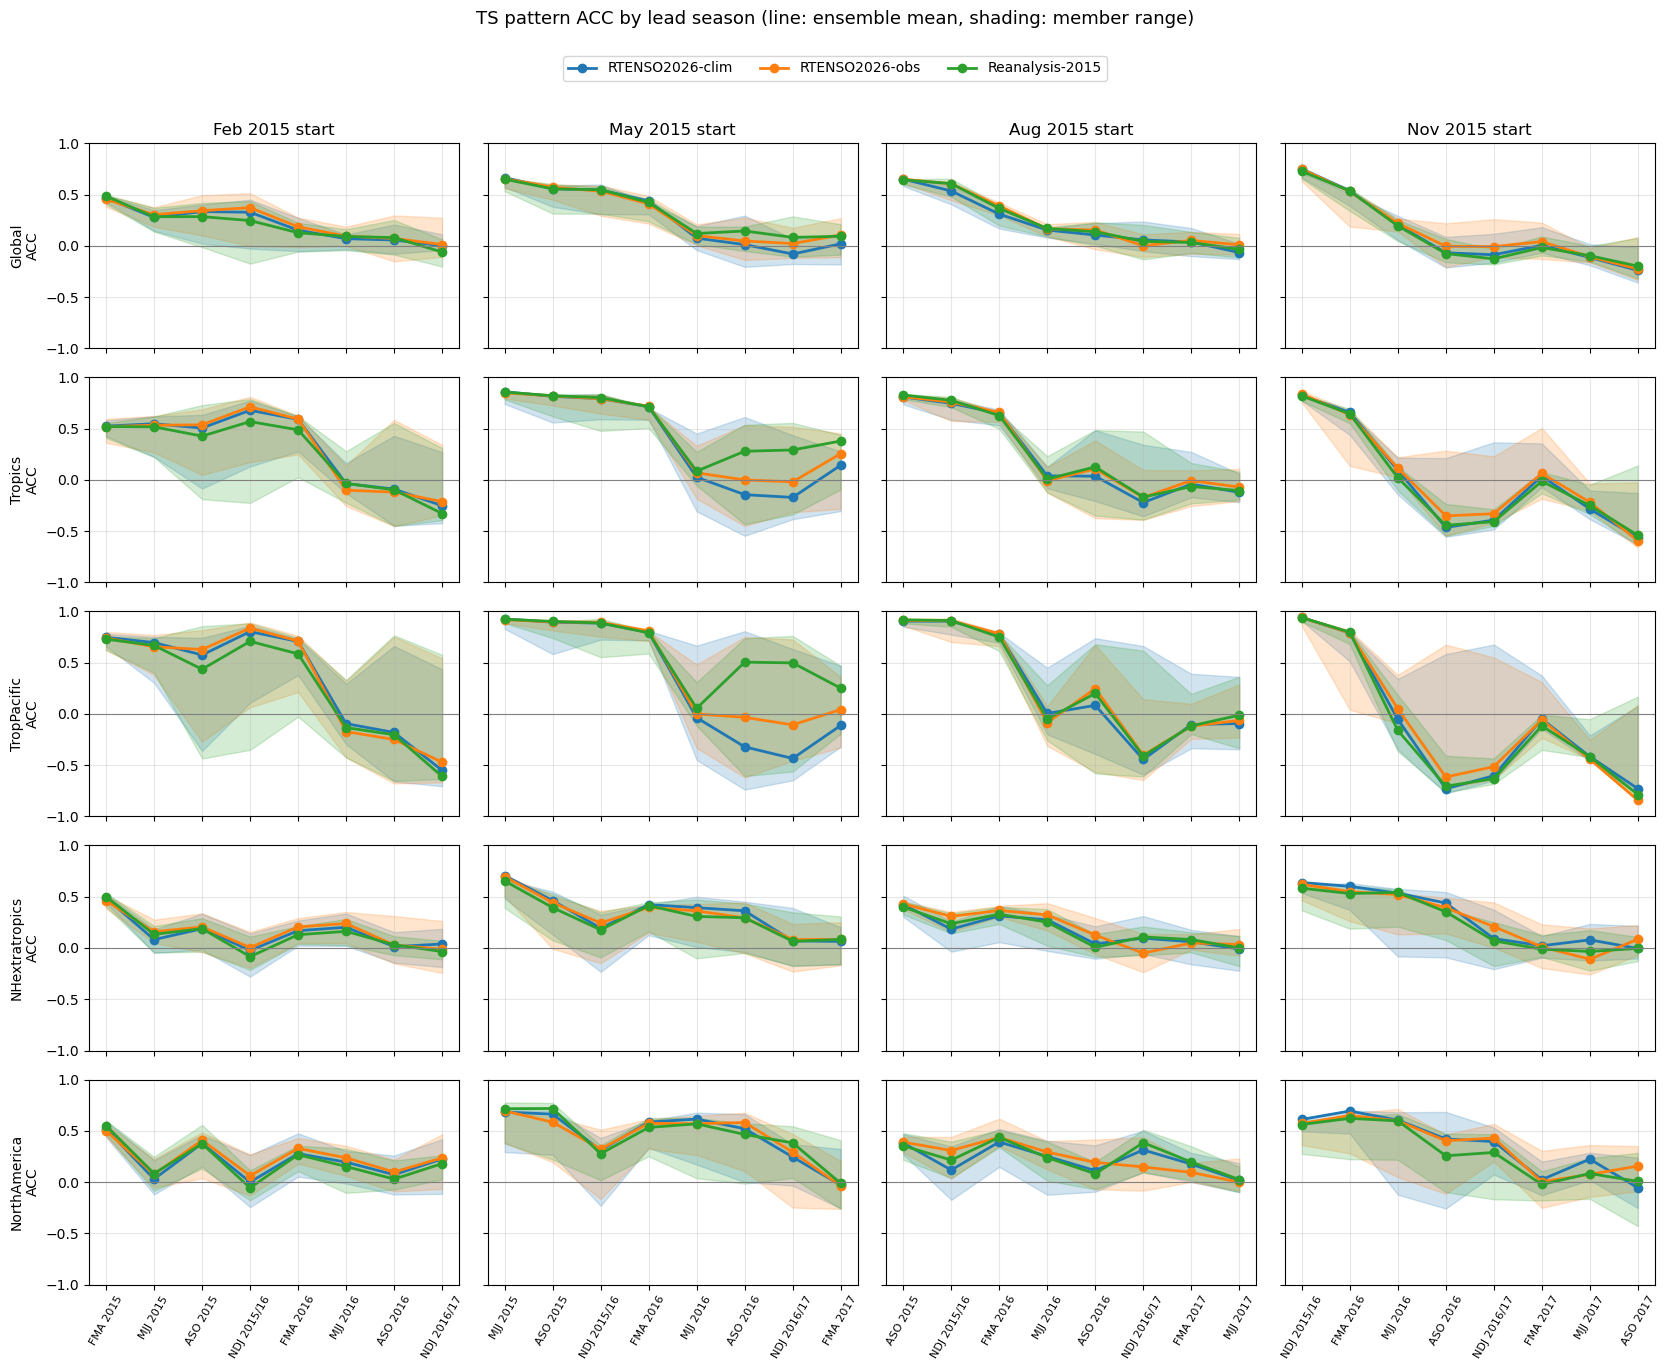

/global/cfs/cdirs/e3sm/www/zhan391/e3sm-s2d_rtenso2026_case/fig_rtenso2026_pattern_rmse_ts.png


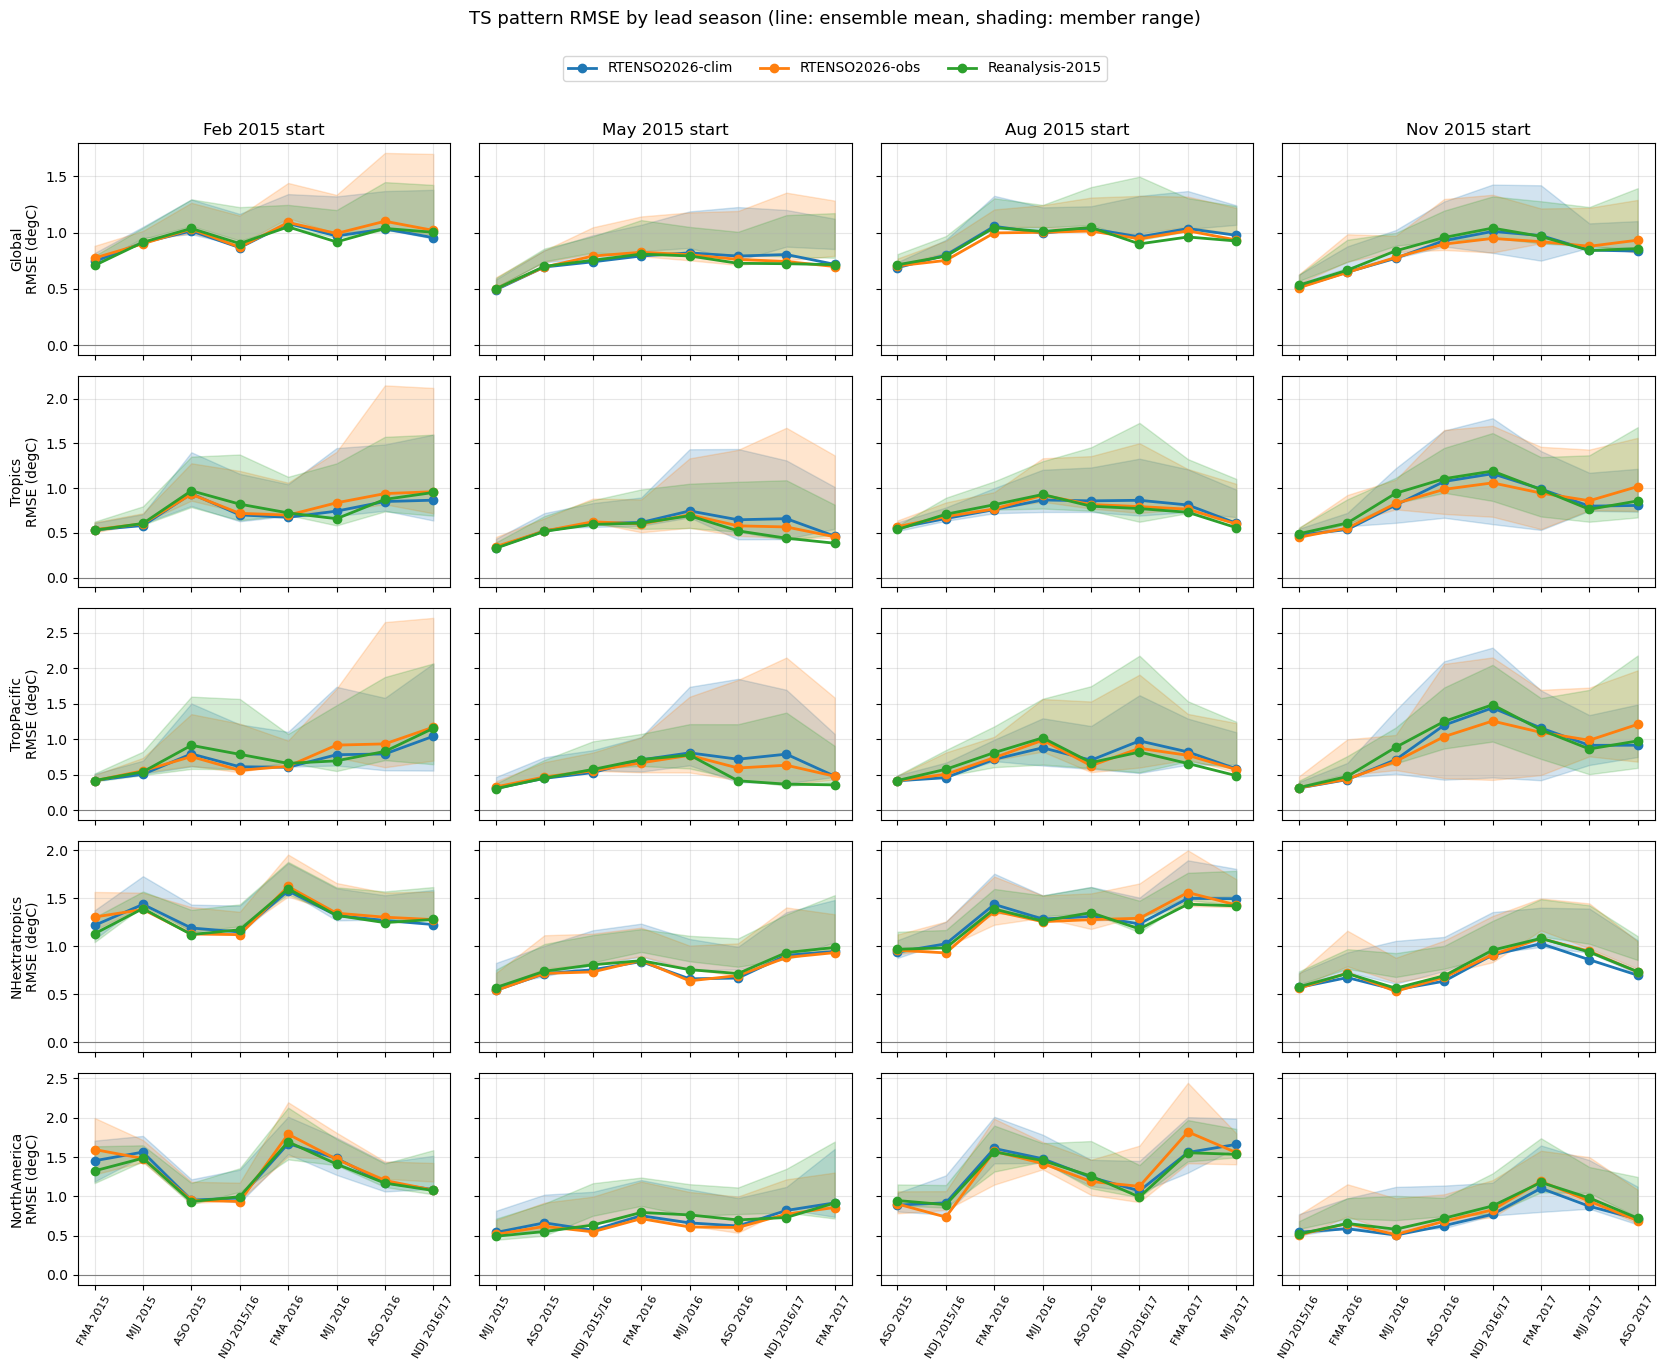

In [7]:
def plot_metric(name, ylabel, ylim=None):
    fig, axes = plt.subplots(len(ACC_REGIONS), len(INIT_MONTHS), figsize=(4.2 * len(INIT_MONTHS), 2.6 * len(ACC_REGIONS)),
                             sharex="col", sharey="row" if ylim is None else True, squeeze=False)
    for col, init in enumerate(INIT_MONTHS):
        for row, region in enumerate(ACC_REGIONS):
            ax = axes[row, col]
            for case in CASES:
                ds = metrics.get((case, init))
                if ds is None:
                    continue
                color = CASES[case]["color"]
                season = ds["season"].values
                members = ds[f"{name}_member"].sel(region=region)
                ax.fill_between(season, members.min("member"), members.max("member"), color=color, alpha=0.2)
                ax.plot(season, ds[f"{name}_ens"].sel(region=region), color=color, marker="o", lw=2, label=case)
            if ylim is not None:
                ax.set_ylim(*ylim)
            ax.axhline(0.0, color="0.5", lw=0.8)
            ax.grid(alpha=0.3)
            if col == 0:
                ax.set_ylabel(f"{region}\n{ylabel}")
            if row == 0:
                ax.set_title(f"{MONTH_NAMES[init]} {CASE_YEAR} start")
            if row == len(ACC_REGIONS) - 1:
                ds = next(metrics[(c, init)] for c in CASES if (c, init) in metrics)
                ax.set_xticks(ds["season"].values)
                ax.set_xticklabels([rc.target_season_label(t) for t in ds["time"].values], rotation=60, fontsize=8)
    handles = {l: h for ax in axes.flat for h, l in zip(*ax.get_legend_handles_labels())}
    fig.legend(handles.values(), handles.keys(), loc="upper center", ncol=len(handles), fontsize=10, bbox_to_anchor=(0.5, 1.02))
    fig.suptitle(f"{FIELD} pattern {name.upper()} by lead season (line: ensemble mean, shading: member range)", fontsize=13, y=1.05)
    fig.tight_layout()
    return fig


fig = plot_metric("acc", "ACC", ylim=(-1.0, 1.0))
print(rc.save_figure(fig, "rtenso2026", "pattern_acc", FIELD))
plt.show()
fig = plot_metric("rmse", f"RMSE ({rc.FIELDS[FIELD]['units']})")
print(rc.save_figure(fig, "rtenso2026", "pattern_rmse", FIELD))
plt.show()

In [8]:
table = []
for (case, init), ds in metrics.items():
    for s, t in zip(ds["season"].values, ds["time"].values):
        table.append({"case": case, "start": MONTH_NAMES[init], "season": int(s), "target": rc.target_season_label(t),
                      **{f"ACC_{r}": round(float(ds["acc_ens"].sel(region=r, season=s)), 3) for r in ACC_REGIONS}})
acc_table = pd.DataFrame(table)
acc_table.to_csv(OUTDIR / f"RTENSO2026_case_{FIELD}_pattern_acc.csv", index=False)
acc_table.pivot_table(index=["start", "season", "target"], columns="case", values="ACC_Global")

case                      RTENSO2026-clim  RTENSO2026-obs  Reanalysis-2015
start season target                                                       
Aug   1      ASO 2015               0.651           0.650            0.644
      2      NDJ 2015/16            0.536           0.605            0.607
      3      FMA 2016               0.310           0.389            0.366
      4      MJJ 2016               0.154           0.166            0.170
      5      ASO 2016               0.106           0.155            0.137
      6      NDJ 2016/17            0.058           0.001            0.044
      7      FMA 2017               0.038           0.053            0.033
      8      MJJ 2017              -0.065           0.010           -0.034
Feb   1      FMA 2015               0.468           0.454            0.484
      2      MJJ 2015               0.277           0.304            0.284
      3      ASO 2015               0.334           0.343            0.285
      4      NDJ 2015/16            0.328           0.373            0.247
      5      FMA 2016               0.152           0.186            0.128
      6      MJJ 2016               0.070           0.095            0.092
      7      ASO 2016               0.057           0.072            0.081
      8      NDJ 2016/17            0.002           0.013           -0.060
May   1      MJJ 2015               0.667           0.655            0.650
      2      ASO 2015               0.557           0.572            0.556
      3      NDJ 2015/16            0.544           0.533            0.547
      4      FMA 2016               0.438           0.409            0.424
      5      MJJ 2016               0.075           0.100            0.120
      6      ASO 2016               0.012           0.047            0.145
      7      NDJ 2016/17           -0.080           0.023            0.083
      8      FMA 2017               0.020           0.106            0.093
Nov   1      NDJ 2015/16            0.751           0.749            0.728
      2      FMA 2016               0.538           0.530            0.535
      3      MJJ 2016               0.206           0.221            0.195
      4      ASO 2016              -0.067          -0.004           -0.075
      5      NDJ 2016/17           -0.087          -0.007           -0.126
      6      FMA 2017               0.006           0.042           -0.016
      7      MJJ 2017              -0.114          -0.107           -0.096
      8      ASO 2017              -0.239          -0.226           -0.198